<a href="https://colab.research.google.com/github/subhajitnaskarns-prog/spotify/blob/main/Spotify_dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Libraries
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import warnings
warnings.filterwarnings('ignore')


In [ ]:
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from sklearn.model_selection import train_test_split


In [ ]:
# Dataset upload
df= pd.read_csv("dataset.csv")

In [ ]:
#Print 5 rows
print("First 5 rows: ")
print(df.head())


First 5 rows: 
   Unnamed: 0                track_id                 artists  \
0           0  5SuOikwiRyPMVoIQDJUgSV             Gen Hoshino   
1           1  4qPNDBW1i3p13qLCt0Ki3A            Ben Woodward   
2           2  1iJBSr7s7jYXzM8EGcbK5b  Ingrid Michaelson;ZAYN   
3           3  6lfxq3CG4xtTiEg7opyCyx            Kina Grannis   
4           4  5vjLSffimiIP26QG5WcN2K        Chord Overstreet   

                                          album_name  \
0                                             Comedy   
1                                   Ghost (Acoustic)   
2                                     To Begin Again   
3  Crazy Rich Asians (Original Motion Picture Sou...   
4                                            Hold On   

                   track_name  popularity  duration_ms  explicit  \
0                      Comedy          73       230666     False   
1            Ghost - Acoustic          55       149610     False   
2              To Begin Again          57       21082

In [ ]:
print(df.tail())

        Unnamed: 0                track_id           artists  \
113995      113995  2C3TZjDRiAzdyViavDJ217     Rainy Lullaby   
113996      113996  1hIz5L4IB9hN3WRYPOCGPw     Rainy Lullaby   
113997      113997  6x8ZfSoqDjuNa5SVP5QjvX     Cesária Evora   
113998      113998  2e6sXL2bYv4bSz6VTdnfLs  Michael W. Smith   
113999      113999  2hETkH7cOfqmz3LqZDHZf5     Cesária Evora   

                                               album_name  \
113995  #mindfulness - Soft Rain for Mindful Meditatio...   
113996  #mindfulness - Soft Rain for Mindful Meditatio...   
113997                                            Best Of   
113998                                  Change Your World   
113999                                     Miss Perfumado   

                 track_name  popularity  duration_ms  explicit  danceability  \
113995  Sleep My Little Boy          21       384999     False         0.172   
113996     Water Into Light          22       385000     False         0.174   
113997  

In [ ]:
#Dataset size
print("Shape of dataset: ",df.shape)
print("Number of rows: ",df.shape[0])


Shape of dataset:  (114000, 21)
Number of rows:  114000


In [ ]:
#Dataset Information
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  str    
 2   artists           113999 non-null  str    
 3   album_name        113999 non-null  str    
 4   track_name        113999 non-null  str    
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-null  float64
 15  instrumentalness  114000 non-null  float64
 16  liveness          114000 non-nu

In [ ]:
#statistical Summary
df.describe()

,Unnamed: 0,popularity,duration_ms,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
count,114000.000000,114000.000000,1.140000e+05,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000
mean,56999.500000,33.238535,2.280292e+05,0.566800,0.641383,5.309140,-8.258960,0.637553,0.084652,0.314910,0.156050,0.213553,0.474068,122.147837,3.904035
std,32909.109681,22.305078,1.072977e+05,0.173542,0.251529,3.559987,5.029337,0.480709,0.105732,0.332523,0.309555,0.190378,0.259261,29.978197,0.432621
min,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,-49.531000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,28499.750000,17.000000,1.740660e+05,0.456000,0.472000,2.000000,-10.013000,0.000000,0.035900,0.016900,0.000000,0.098000,0.260000,99.218750,4.000000
50%,56999.500000,35.000000,2.129060e+05,0.580000,0.685000,5.000000,-7.004000,1.000000,0.048900,0.169000,0.000042,0.132000,0.464000,122.017000,4.000000
75%,85499.250000,50.000000,2.615060e+05,0.695000,0.854000,8.000000,-5.003000,1.000000,0.084500,0.598000,0.049000,0.273000,0.683000,140.071000,4.000000
max,113999.000000,100.000000,5.237295e+06,0.985000,1.000000,11.000000,4.532000,1.000000,0.965000,0.996000,1.000000,1.000000,0.995000,243.372000,5.000000


In [ ]:
#Types of columns
print(df.dtypes)

Unnamed: 0            int64
track_id                str
artists                 str
album_name              str
track_name              str
popularity            int64
duration_ms           int64
explicit               bool
danceability        float64
energy              float64
key                   int64
loudness            float64
mode                  int64
speechiness         float64
acousticness        float64
instrumentalness    float64
liveness            float64
valence             float64
tempo               float64
time_signature        int64
track_genre             str
dtype: object


In [ ]:
# All columns name
print(df.columns)

Index(['Unnamed: 0', 'track_id', 'artists', 'album_name', 'track_name',
       'popularity', 'duration_ms', 'explicit', 'danceability', 'energy',
       'key', 'loudness', 'mode', 'speechiness', 'acousticness',
       'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature',
       'track_genre'],
      dtype='str')


In [ ]:
#statistical Summary
df.describe(include="all")

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
count,114000.000000,114000,113999,113999,113999,114000.000000,1.140000e+05,114000,114000.000000,114000.000000,...,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000
unique,NaN,89741,31437,46589,73608,NaN,NaN,2,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,114
top,NaN,6S3JlDAGk3uu3NtZbPnuhS,The Beatles,Alternative Christmas 2022,Run Rudolph Run,NaN,NaN,False,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,acoustic
freq,NaN,9,279,195,151,NaN,NaN,104253,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1000
mean,56999.500000,NaN,NaN,NaN,NaN,33.238535,2.280292e+05,NaN,0.566800,0.641383,...,-8.258960,0.637553,0.084652,0.314910,0.156050,0.213553,0.474068,122.147837,3.904035,NaN
std,32909.109681,NaN,NaN,NaN,NaN,22.305078,1.072977e+05,NaN,0.173542,0.251529,...,5.029337,0.480709,0.105732,0.332523,0.309555,0.190378,0.259261,29.978197,0.432621,NaN
min,0.000000,NaN,NaN,NaN,NaN,0.000000,0.000000e+00,NaN,0.000000,0.000000,...,-49.531000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN
25%,28499.750000,NaN,NaN,NaN,NaN,17.000000,1.740660e+05,NaN,0.456000,0.472000,...,-10.013000,0.000000,0.035900,0.016900,0.000000,0.098000,0.260000,99.218750,4.000000,NaN
50%,56999.500000,NaN,NaN,NaN,NaN,35.000000,2.129060e+05,NaN,0.580000,0.685000,...,-7.004000,1.000000,0.048900,0.169000,0.000042,0.132000,0.464000,122.017000,4.000000,NaN
75%,85499.250000,NaN,NaN,NaN,NaN,50.000000,2.615060e+05,NaN,0.695000,0.854000,...,-5.003000,1.000000,0.084500,0.598000,0.049000,0.273000,0.683000,140.071000,4.000000,NaN


In [ ]:
#Missing Values Check
df.isnull().sum().sum()

np.int64(3)

In [ ]:
#Duplicate Check
print("Duplicate rows: ", df.duplicated().sum())

Duplicate rows:  0


In [ ]:
#Missing Values Check
df.isnull().sum()

Unnamed: 0          0
track_id            0
artists             1
album_name          1
track_name          1
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
dtype: int64

In [ ]:
#Duplicate Check
print("Duplicate rows: ", df.duplicated().sum())

Duplicate rows:  0


In [ ]:
#Omit Duplicate Values
print("Original shape: ",df.shape)
df_drop = df.dropna()
print("Shape after removing missing values: ", df_drop.shape)

Original shape:  (114000, 21)
Shape after removing missing values:  (113999, 21)


In [ ]:
print("\nMissing values after dropna():")
print(df_drop.isnull().sum())



Missing values after dropna():
Unnamed: 0          0
track_id            0
artists             0
album_name          0
track_name          0
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
dtype: int64


In [ ]:
df.isnull().sum()

Unnamed: 0          0
track_id            0
artists             1
album_name          1
track_name          1
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
dtype: int64

In [ ]:

Q1= df["speechiness"].quantile(0.25)
Q3= df["speechiness"].quantile(0.75)


In [ ]:
IQR= Q3-Q1
lower_limit = Q1 -1.5*IQR
upper_limit = Q3+1.5*IQR

print("Q1 =",Q1)
print("Q3=", Q3)
print("IQR", IQR)
print("Lower Limit",lower_limit)
print("Upper Limit",upper_limit)



Q1 = 0.0359
Q3= 0.0845
IQR 0.048600000000000004
Lower Limit -0.037000000000000005
Upper Limit 0.1574


In [ ]:
outliers = df[
    (df["speechiness"] < lower_limit) |
    (df["speechiness"] > upper_limit)
]
print(outliers)



        Unnamed: 0                track_id                        artists  \
370            370  1wSZdWFZphxDh6iJhWlIUi                   Ben Woodward   
692            692  5CU7ewecONNlWAJHu04HJQ        The Bridge City Sinners   
713            713  1z2fSrYZqrO5tMqzULn9OD                   Tyrone Wells   
768            768  1m3Lsbhkn6yL8apzsCiukd                   Ben Woodward   
815            815  10a6GUpyRLdfadUPRL5wBg  Postcards & Polaroids;Sad Boy   
...            ...                     ...                            ...   
113549      113549  60iVN2c4KpoB9teVSBzmzt     Reiki Armonía;Paz Interior   
113818      113818  7iBIuW0do6NaHXQ7Jueu67             for KING & COUNTRY   
113923      113923  4wl9wFhVgT4ucd72OEpEeZ  for KING & COUNTRY;Dante Bowe   
113940      113940  3Fj6wu6AAnltIyS2jNbqiG                   Flor de Loto   
113981      113981  1pBc7W7UQacUeQ6kBVlN9f                  Planetshakers   

                                               album_name  \
370           

In [ ]:
original_outliers = df[
    (df["speechiness"] < lower_limit) |
    (df["speechiness"] > upper_limit)
].copy()


In [ ]:
#Store original shape
original_shape = df.shape
#remove outliers
df = df[
    (df["speechiness"] >= lower_limit) &
    (df["speechiness"] <= upper_limit)
]
#store new shape
new_shape = df.shape
print("\nOriginal Outliers: ")
print(original_outliers)

print("\nDataset Shape Before Treatment: ", original_shape)
print("Dataset Shape After Treatment: ", new_shape)



Original Outliers: 
        Unnamed: 0                track_id                        artists  \
370            370  1wSZdWFZphxDh6iJhWlIUi                   Ben Woodward   
692            692  5CU7ewecONNlWAJHu04HJQ        The Bridge City Sinners   
713            713  1z2fSrYZqrO5tMqzULn9OD                   Tyrone Wells   
768            768  1m3Lsbhkn6yL8apzsCiukd                   Ben Woodward   
815            815  10a6GUpyRLdfadUPRL5wBg  Postcards & Polaroids;Sad Boy   
...            ...                     ...                            ...   
113549      113549  60iVN2c4KpoB9teVSBzmzt     Reiki Armonía;Paz Interior   
113818      113818  7iBIuW0do6NaHXQ7Jueu67             for KING & COUNTRY   
113923      113923  4wl9wFhVgT4ucd72OEpEeZ  for KING & COUNTRY;Dante Bowe   
113940      113940  3Fj6wu6AAnltIyS2jNbqiG                   Flor de Loto   
113981      113981  1pBc7W7UQacUeQ6kBVlN9f                  Planetshakers   

                                               album_n

In [ ]:
print("\nNumber of Rows Removed: ",
      original_shape[0] - new_shape[0])

print("\nUpdated Dataset:")
print(df)



Number of Rows Removed:  13211

Updated Dataset:
        Unnamed: 0                track_id                 artists  \
0                0  5SuOikwiRyPMVoIQDJUgSV             Gen Hoshino   
1                1  4qPNDBW1i3p13qLCt0Ki3A            Ben Woodward   
2                2  1iJBSr7s7jYXzM8EGcbK5b  Ingrid Michaelson;ZAYN   
3                3  6lfxq3CG4xtTiEg7opyCyx            Kina Grannis   
4                4  5vjLSffimiIP26QG5WcN2K        Chord Overstreet   
...            ...                     ...                     ...   
113995      113995  2C3TZjDRiAzdyViavDJ217           Rainy Lullaby   
113996      113996  1hIz5L4IB9hN3WRYPOCGPw           Rainy Lullaby   
113997      113997  6x8ZfSoqDjuNa5SVP5QjvX           Cesária Evora   
113998      113998  2e6sXL2bYv4bSz6VTdnfLs        Michael W. Smith   
113999      113999  2hETkH7cOfqmz3LqZDHZf5           Cesária Evora   

                                               album_name  \
0                                               

In [ ]:
print(df.duplicated().sum())

0


In [ ]:
df= df.drop_duplicates()
print(df.dtypes)
print(df["track_id"].unique())
print(df["artists"].unique())
print(df["track_genre"].unique())
print(df["track_name"].unique())
print(df["album_name"].unique())

Unnamed: 0            int64
track_id                str
artists                 str
album_name              str
track_name              str
popularity            int64
duration_ms           int64
explicit               bool
danceability        float64
energy              float64
key                   int64
loudness            float64
mode                  int64
speechiness         float64
acousticness        float64
instrumentalness    float64
liveness            float64
valence             float64
tempo               float64
time_signature        int64
track_genre             str
dtype: object
<ArrowStringArray>
['5SuOikwiRyPMVoIQDJUgSV', '4qPNDBW1i3p13qLCt0Ki3A', '1iJBSr7s7jYXzM8EGcbK5b',
 '6lfxq3CG4xtTiEg7opyCyx', '5vjLSffimiIP26QG5WcN2K', '01MVOl9KtVTNfFiBU9I7dc',
 '6Vc5wAMmXdKIAM7WUoEb7N', '1EzrEOXmMH3G43AXT1y7pA', '0IktbUcnAGrvD03AWnz3Q8',
 '7k9GuJYLp2AzqokyEdwEw2',
 ...
 '2A4dSiJmbviL56CBupkh6C', '0CE0Y6GM75cbrqao8EOAlW', '3FjOBB4EyIXHYUtSgrIdY9',
 '4OkMK49i3NApR1KsAIsTf6', '4Wb

In [ ]:
df= df.drop_duplicates()
print(df.dtypes)
print(df["track_id"].unique())
print(df["artists"].unique())
print(df["track_genre"].unique())
print(df["track_name"].unique())
print(df["album_name"].unique())

print(df["track_id"].value_counts())
print(df["artists"].value_counts())
print(df["track_genre"].value_counts())
print(df["track_name"].value_counts())
print(df["album_name"].value_counts())
#label encoding
le = LabelEncoder()
df["artists_encoded"] = le.fit_transform(df["artists"])
print(df[["artists","artists_encoded"]].head())


Unnamed: 0            int64
track_id                str
artists                 str
album_name              str
track_name              str
popularity            int64
duration_ms           int64
explicit               bool
danceability        float64
energy              float64
key                   int64
loudness            float64
mode                  int64
speechiness         float64
acousticness        float64
instrumentalness    float64
liveness            float64
valence             float64
tempo               float64
time_signature        int64
track_genre             str
dtype: object
<ArrowStringArray>
['5SuOikwiRyPMVoIQDJUgSV', '4qPNDBW1i3p13qLCt0Ki3A', '1iJBSr7s7jYXzM8EGcbK5b',
 '6lfxq3CG4xtTiEg7opyCyx', '5vjLSffimiIP26QG5WcN2K', '01MVOl9KtVTNfFiBU9I7dc',
 '6Vc5wAMmXdKIAM7WUoEb7N', '1EzrEOXmMH3G43AXT1y7pA', '0IktbUcnAGrvD03AWnz3Q8',
 '7k9GuJYLp2AzqokyEdwEw2',
 ...
 '2A4dSiJmbviL56CBupkh6C', '0CE0Y6GM75cbrqao8EOAlW', '3FjOBB4EyIXHYUtSgrIdY9',
 '4OkMK49i3NApR1KsAIsTf6', '4Wb

In [ ]:
df["track_genre_encoded"] = le.fit_transform(df["track_genre"])
print(df[["track_genre", "track_genre_encoded"]].head())

df["track_name_encoded"] = le.fit_transform(df["track_name"])
print(df[["track_name", "track_name_encoded"]].head())

df["artists_encoded"] = le.fit_transform(df["artists"])
print(df[["artists", "artists_encoded"]].head())


  track_genre  track_genre_encoded
0    acoustic                    0
1    acoustic                    0
2    acoustic                    0
3    acoustic                    0
4    acoustic                    0
                   track_name  track_name_encoded
0                      Comedy               10151
1            Ghost - Acoustic               19531
2              To Begin Again               53051
3  Can't Help Falling In Love                8270
4                     Hold On               22288
                  artists  artists_encoded
0             Gen Hoshino             9079
1            Ben Woodward             2915
2  Ingrid Michaelson;ZAYN            10922
3            Kina Grannis            13081
4        Chord Overstreet             4676


In [ ]:
df.head()

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre,artists_encoded,track_genre_encoded,track_name_encoded
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic,9079,0,10151
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic,2915,0,19531
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic,10922,0,53051
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic,13081,0,8270
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic,4676,0,22288


In [ ]:
#Normalization
scaler = MinMaxScaler()
df["danceability_normalized"] = scaler.fit_transform(
     df[["danceability"]]
)
print(
     df[
         ["danceability", "danceability_normalized"]
     ].head()
)


   danceability  danceability_normalized
0         0.676                 0.686992
1         0.420                 0.426829
2         0.438                 0.445122
3         0.266                 0.270325
4         0.618                 0.628049


In [ ]:
#Normalization
scaler = MinMaxScaler()
df["acousticness_normalized"] = scaler.fit_transform(
     df[["acousticness"]]
)
print(
     df[
         ["acousticness", "acousticness_normalized"]
     ].head()
)


   acousticness  acousticness_normalized
0        0.0322                 0.032329
1        0.9240                 0.927711
2        0.2100                 0.210843
3        0.9050                 0.908635
4        0.4690                 0.470884


In [ ]:
scaler = StandardScaler()
df["acousticness_standardized"] = scaler.fit_transform(
     df[["acousticness"]]
)
print(
     df[
         ["acousticness", "acousticness_standardized"]
     ].head()
)


   acousticness  acousticness_standardized
0        0.0322                  -0.853464
1        0.9240                   1.795169
2        0.2100                  -0.325400
3        0.9050                   1.738739
4        0.4690                   0.443826


In [ ]:
scaler = StandardScaler()
df["danceability_standardized"] = scaler.fit_transform(
     df[["danceability"]]
)
print(
     df[
         ["danceability", "danceability_standardized"]
     ].head()
)


   danceability  danceability_standardized
0         0.676                   0.681688
1         0.420                  -0.811291
2         0.438                  -0.706316
3         0.266                  -1.709411
4         0.618                   0.343435


In [ ]:
#Numerical features select & check
features = [
    'danceability',
    'energy',
    'loudness',
    'speechiness',
    'acousticness',
    'instrumentalness',
    'liveness',
    'valence',
    'tempo'
]

df[features].head()

,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
0,0.676,0.4610,-6.746,0.1430,0.0322,0.000001,0.3580,0.715,87.917
1,0.420,0.1660,-17.235,0.0763,0.9240,0.000006,0.1010,0.267,77.489
2,0.438,0.3590,-9.734,0.0557,0.2100,0.000000,0.1170,0.120,76.332
3,0.266,0.0596,-18.515,0.0363,0.9050,0.000071,0.1320,0.143,181.740
4,0.618,0.4430,-9.681,0.0526,0.4690,0.000000,0.0829,0.167,119.949


In [ ]:
#Create Popularity
def popularity_category(score):
    if score >= 70:
        return "Popular"
    elif score >= 40:
        return "Moderately Popular"
    else:
        return "Not Popular"

df['popularity_category'] = df['popularity'].apply(popularity_category)

df[['popularity', 'popularity_category']].head(20)

,popularity,popularity_category
0,73,Popular
1,55,Moderately Popular
2,57,Moderately Popular
3,71,Popular
4,82,Popular
5,58,Moderately Popular
6,74,Popular
7,80,Popular
8,74,Popular
9,56,Moderately Popular


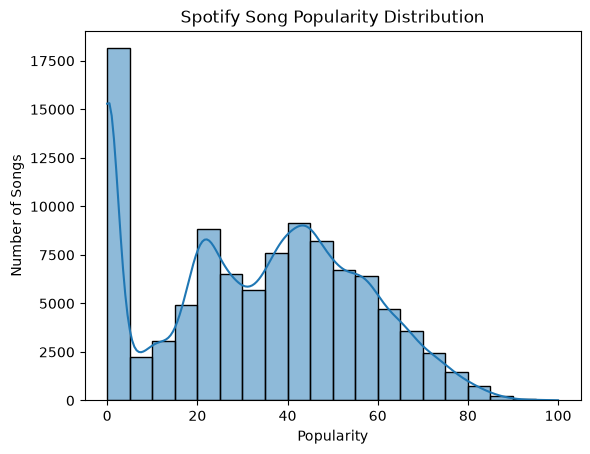

In [ ]:
#EDA Popularity Distributionplt.figure(figsize=(10,5))

sns.histplot(
    df['popularity'],
    bins=20,
    kde=True
)

plt.title("Spotify Song Popularity Distribution")
plt.xlabel("Popularity")
plt.ylabel("Number of Songs")

plt.show()

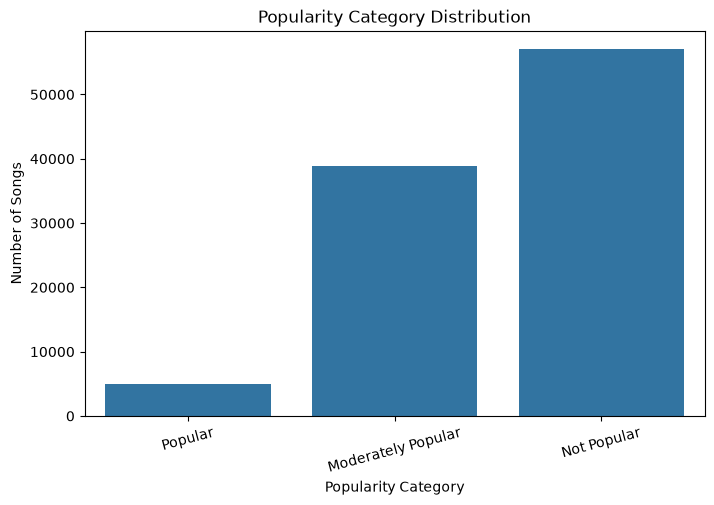

In [ ]:
#Popularity classes Visualization
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x='popularity_category'
)

plt.title("Popularity Category Distribution")
plt.xlabel("Popularity Category")
plt.ylabel("Number of Songs")

plt.xticks(rotation=15)

plt.show()

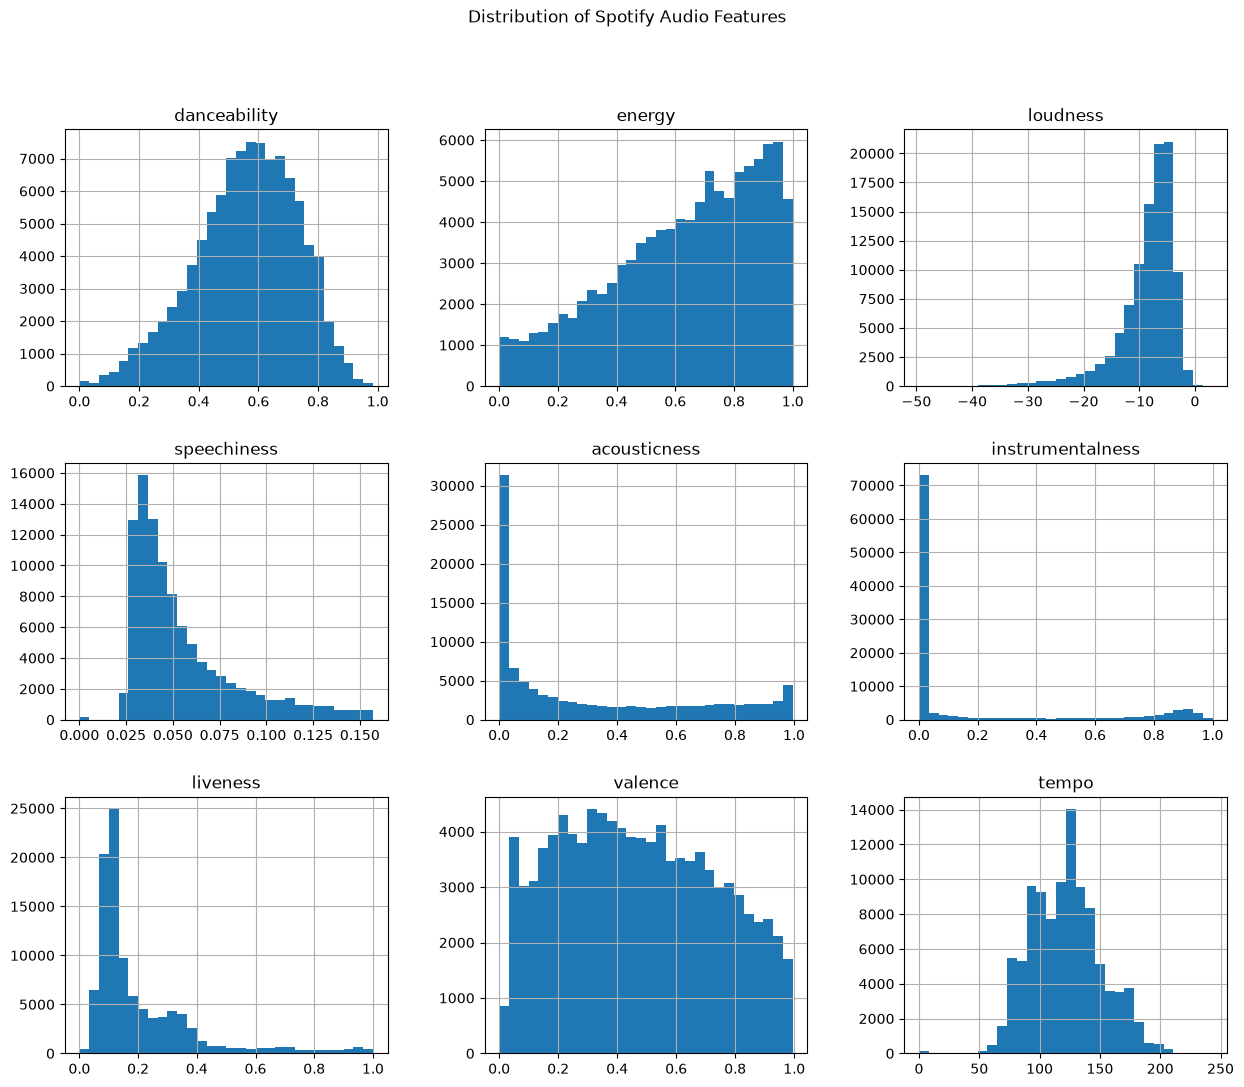

In [ ]:
#Feature Distribution
df[features].hist(
    figsize=(15,12),
    bins=30
)

plt.suptitle("Distribution of Spotify Audio Features")

plt.show()

In [ ]:
scaler = MinMaxScaler()
df_normalized = df.copy()
df_normalized[features] = scaler.fit_transform(
    df_normalized[features]
)


In [ ]:
print( df_normalized[features].head())

   danceability  energy  loudness  speechiness  acousticness  \
0      0.686992  0.4610  0.812060     0.910828      0.032329   
1      0.426829  0.1660  0.612979     0.485987      0.927711   
2      0.445122  0.3590  0.755348     0.354777      0.210843   
3      0.270325  0.0596  0.588684     0.231210      0.908635   
4      0.628049  0.4430  0.756354     0.335032      0.470884   

   instrumentalness  liveness   valence     tempo  
0          0.000001    0.3580  0.718593  0.361245  
1          0.000006    0.1010  0.268342  0.318397  
2          0.000000    0.1170  0.120603  0.313643  
3          0.000071    0.1320  0.143719  0.746758  
4          0.000000    0.0829  0.167839  0.492863  


In [ ]:
scaler = StandardScaler()
df_standardized = df.copy()
df_standardized[features] = scaler.fit_transform(
    df_standardized[features]
)
print(df_standardized[features].head())

   danceability    energy  loudness  speechiness  acousticness  \
0      0.681688 -0.667873  0.325502     3.031393     -0.853464   
1     -0.811291 -1.825531 -1.721082     0.724359      1.795169   
2     -0.706316 -1.068148 -0.257508     0.011842     -0.325400   
3     -1.709411 -2.243073 -1.970832    -0.659170      1.738739   
4      0.343435 -0.738509 -0.247167    -0.095382      0.443826   

   instrumentalness  liveness   valence     tempo  
0         -0.523365  0.825712  0.940200 -1.156892  
1         -0.523351 -0.577777 -0.776565 -1.513724  
2         -0.523369 -0.490400 -1.339878 -1.553315  
3         -0.523146 -0.408484 -1.251741  2.053604  
4         -0.523369 -0.676621 -1.159771 -0.060800  


In [ ]:
X = df[
    [
    "danceability",
    "acousticness",
    "valence",
    "tempo"
    ]
]
y = df["track_genre"]


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
   X,
   y,
   test_size=0.20,
   random_state=42
)

print("Training data: ",X_train.shape)

print("Testing data: ", X_test.shape)


Training data:  (80631, 4)
Testing data:  (20158, 4)


In [ ]:
print(X_train.head())

       danceability  acousticness  valence    tempo
76375         0.289        0.9460   0.0806   73.889
77667         0.469        0.6260   0.6900   85.828
81380         0.539        0.6510   0.5560   75.899
29702         0.478        0.0362   0.2560  151.997
39507         0.638        0.0476   0.5110  127.012


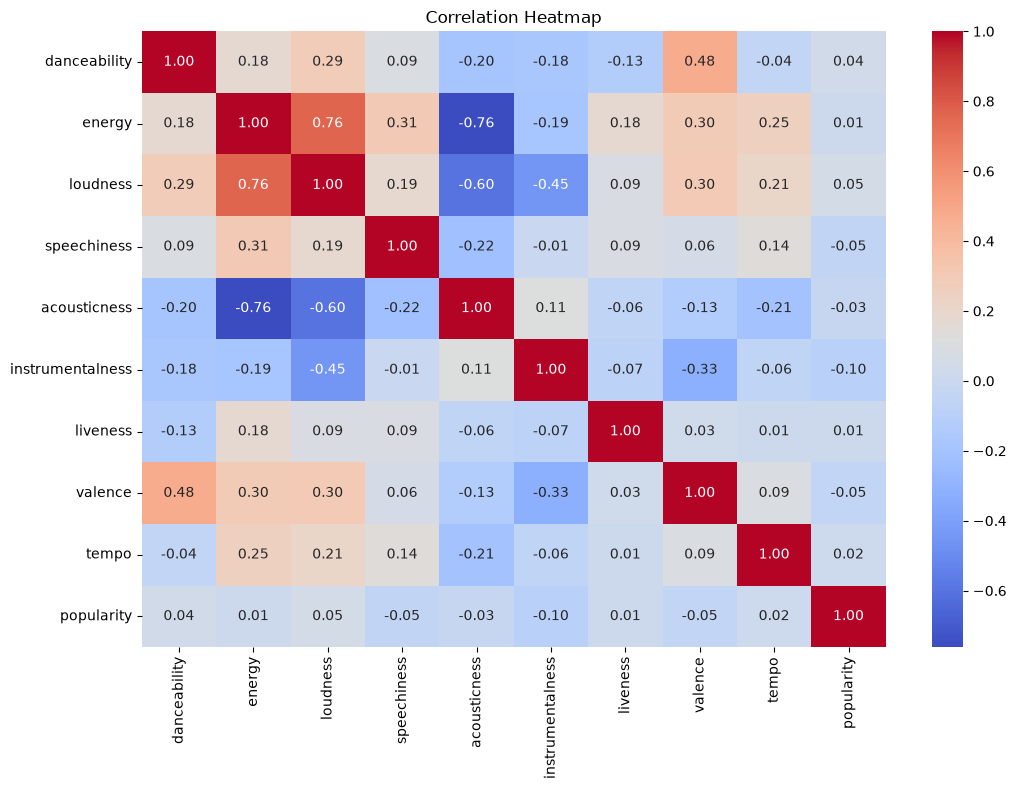

In [ ]:
#feature selection
#Correlation Heatmap
plt.figure(figsize=(12,8))

correlation = df[features + ['popularity']].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap")

plt.show()

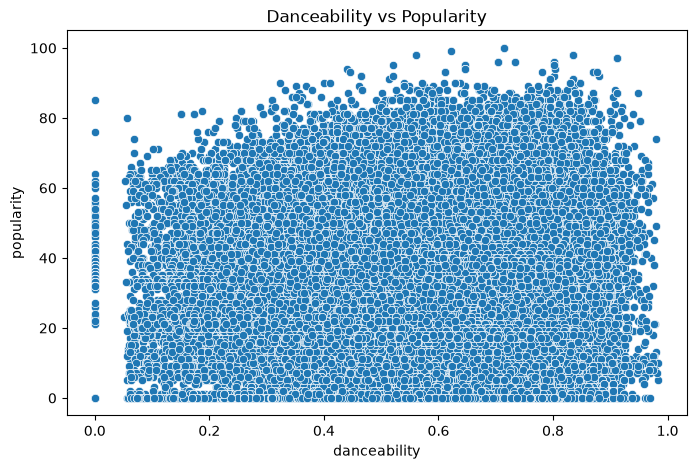

In [ ]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x='danceability',
    y='popularity'
)

plt.title("Danceability vs Popularity")
plt.show()

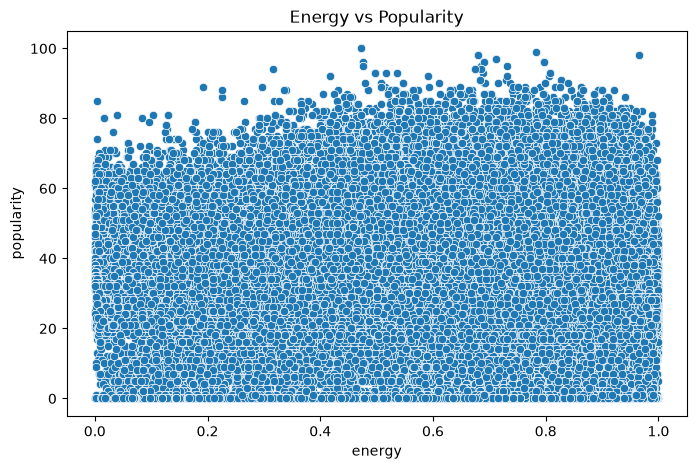

In [ ]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x='energy',
    y='popularity'
)

plt.title("Energy vs Popularity")
plt.show()

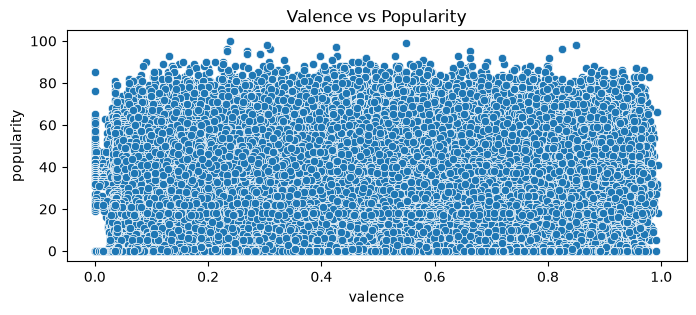

In [ ]:
plt.figure(figsize=(8,3))

sns.scatterplot(
    data=df,
    x='valence',
    y='popularity'
)

plt.title("Valence vs Popularity")
plt.show()

In [ ]:
X = df[features]

y = df['popularity_category']

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (100789, 9)
y shape: (100789,)


In [ ]:
#Train-Test-split & checking
X_train, X_test, y_train, y_test = train_test_split(
   X,
   y,
   test_size=0.20,
   random_state=42

)

print("Training data: ",X_train.shape)

print("Testing data: ", X_test.shape)


Training data:  (80631, 9)
Testing data:  (20158, 9)


In [ ]:
#Feature Scaling using Standard Scaler
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled training data:", X_train_scaled.shape)
print("Scaled testing data:", X_test_scaled.shape)

Scaled training data: (80631, 9)
Scaled testing data: (20158, 9)


In [ ]:
#Logistic Regression & Prediction
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(
    X_train_scaled,
    y_train
)
y_pred_logistic = logistic_model.predict(X_test_scaled)

print("===== Logistic Regression =====")
print("Model trained successfully!")
print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)
print("Predictions generated:", len(y_pred_logistic))
print("First 10 predictions:")
print(y_pred_logistic[:10])

===== Logistic Regression =====
Model trained successfully!
Training data shape: (80631, 9)
Testing data shape: (20158, 9)
Predictions generated: 20158
First 10 predictions:
['Moderately Popular' 'Not Popular' 'Not Popular' 'Not Popular'
 'Moderately Popular' 'Moderately Popular' 'Moderately Popular'
 'Not Popular' 'Not Popular' 'Not Popular']


In [ ]:
# Decision Tree & Prediction
from sklearn.tree import DecisionTreeClassifier
decision_tree = DecisionTreeClassifier(
    random_state=42,
    max_depth=10
)
decision_tree.fit(X_train, y_train)
y_pred_tree = decision_tree.predict(X_test)
print("===== Decision Tree =====")
print("Model trained successfully!")
print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)
print("Predictions generated:", len(y_pred_tree))
print("First 10 predictions:")
print(y_pred_tree[:10])

===== Decision Tree =====
Model trained successfully!
Training data shape: (80631, 9)
Testing data shape: (20158, 9)
Predictions generated: 20158
First 10 predictions:
['Not Popular' 'Moderately Popular' 'Not Popular' 'Not Popular'
 'Moderately Popular' 'Moderately Popular' 'Moderately Popular'
 'Not Popular' 'Not Popular' 'Not Popular']


In [ ]:
#Random Forest
from sklearn.ensemble import RandomForestClassifier

random_forest = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

random_forest.fit(X_train, y_train)

y_pred_rf = random_forest.predict(X_test)

print("===== Random Forest =====")
print("Model trained successfully!")
print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)
print("Predictions generated:", len(y_pred_rf))
print("First 10 predictions:")
print(y_pred_rf[:10])

===== Random Forest =====
Model trained successfully!
Training data shape: (80631, 9)
Testing data shape: (20158, 9)
Predictions generated: 20158
First 10 predictions:
['Moderately Popular' 'Moderately Popular' 'Not Popular' 'Not Popular'
 'Moderately Popular' 'Not Popular' 'Moderately Popular' 'Not Popular'
 'Not Popular' 'Not Popular']


In [ ]:
# Model Evaluation Function
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

def evaluate_model(name, y_true, y_pred):

    accuracy = accuracy_score(y_true, y_pred)

    precision = precision_score(
        y_true,
        y_pred,
        average='weighted',
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        average='weighted',
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        average='weighted',
        zero_division=0
    )

    print("=" * 50)
    print(name)
    print("=" * 50)

    print("Accuracy :", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall   :", round(recall, 4))
    print("F1 Score :", round(f1, 4))

    print("\nClassification Report:")
    print(classification_report(y_true, y_pred))

    return accuracy, precision, recall, f1

In [ ]:
#Evaluate Logistic Regression
logistic_results = evaluate_model(
    "Logistic Regression",
    y_test,
    y_pred_logistic
)

Logistic Regression
Accuracy : 0.5822
Precision: 0.5317
Recall   : 0.5822
F1 Score : 0.5229

Classification Report:
                    precision    recall  f1-score   support

Moderately Popular       0.50      0.22      0.31      7654
       Not Popular       0.60      0.87      0.71     11517
           Popular       0.00      0.00      0.00       987

          accuracy                           0.58     20158
         macro avg       0.37      0.36      0.34     20158
      weighted avg       0.53      0.58      0.52     20158



In [ ]:
# Evaluate Decision Tree
logistic_results = evaluate_model(
    "Logistic Regression",
    y_test,
    y_pred_logistic
)

Logistic Regression
Accuracy : 0.5822
Precision: 0.5317
Recall   : 0.5822
F1 Score : 0.5229

Classification Report:
                    precision    recall  f1-score   support

Moderately Popular       0.50      0.22      0.31      7654
       Not Popular       0.60      0.87      0.71     11517
           Popular       0.00      0.00      0.00       987

          accuracy                           0.58     20158
         macro avg       0.37      0.36      0.34     20158
      weighted avg       0.53      0.58      0.52     20158



In [ ]:
#Evaluate Random Forest
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

rf_results = evaluate_model(
    "Random Forest",
    y_test,
    y_pred_rf
)

Random Forest
Accuracy : 0.7588
Precision: 0.7599
Recall   : 0.7588
F1 Score : 0.7564

Classification Report:
                    precision    recall  f1-score   support

Moderately Popular       0.71      0.67      0.69      7654
       Not Popular       0.78      0.84      0.81     11517
           Popular       0.92      0.57      0.71       987

          accuracy                           0.76     20158
         macro avg       0.80      0.69      0.73     20158
      weighted avg       0.76      0.76      0.76     20158



In [ ]:
# Model Comparison
import pandas as pd

results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Decision Tree',
        'Random Forest'
    ],

    'Accuracy': [
        logistic_results[0],
        tree_results[0],
        rf_results[0]
    ],

    'Precision': [
        logistic_results[1],
        tree_results[1],
        rf_results[1]
    ],

    'Recall': [
        logistic_results[2],
        tree_results[2],
        rf_results[2]
    ],

    'F1 Score': [
        logistic_results[3],
        tree_results[3],
        rf_results[3]
    ]
})

print("===== Model Performance Comparison =====")
display(results)

NameError: name 'tree_results' is not defined

In [ ]:
# Model Comparison Graph
import matplotlib.pyplot as plt

results.set_index('Model').plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Machine Learning Model")
plt.ylim(0, 1)

plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

NameError: name 'results' is not defined

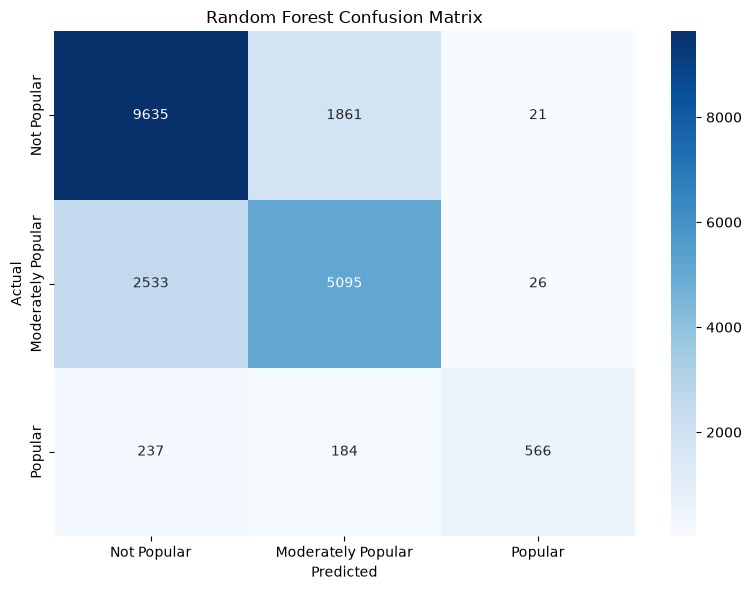

In [ ]:
#Confusion Matrix
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(
    y_test,
    y_pred_rf,
    labels=[
        'Not Popular',
        'Moderately Popular',
        'Popular'
    ]
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=[
        'Not Popular',
        'Moderately Popular',
        'Popular'
    ],
    yticklabels=[
        'Not Popular',
        'Moderately Popular',
        'Popular'
    ]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest Confusion Matrix")

plt.tight_layout()
plt.show()

In [ ]:
#Feature Independence
#1. Calculate Feature Importance
import pandas as pd

importance = pd.DataFrame({
    'Feature': features,
    'Importance': random_forest.feature_importances_
})

importance = importance.sort_values(
    by='Importance',
    ascending=False
)

print("===== Feature Importance =====")
display(importance)

===== Feature Importance =====


,Feature,Importance
7,valence,0.118189
4,acousticness,0.118181
8,tempo,0.116907
0,danceability,0.116368
2,loudness,0.115371
1,energy,0.112904
6,liveness,0.109882
3,speechiness,0.108024
5,instrumentalness,0.084173


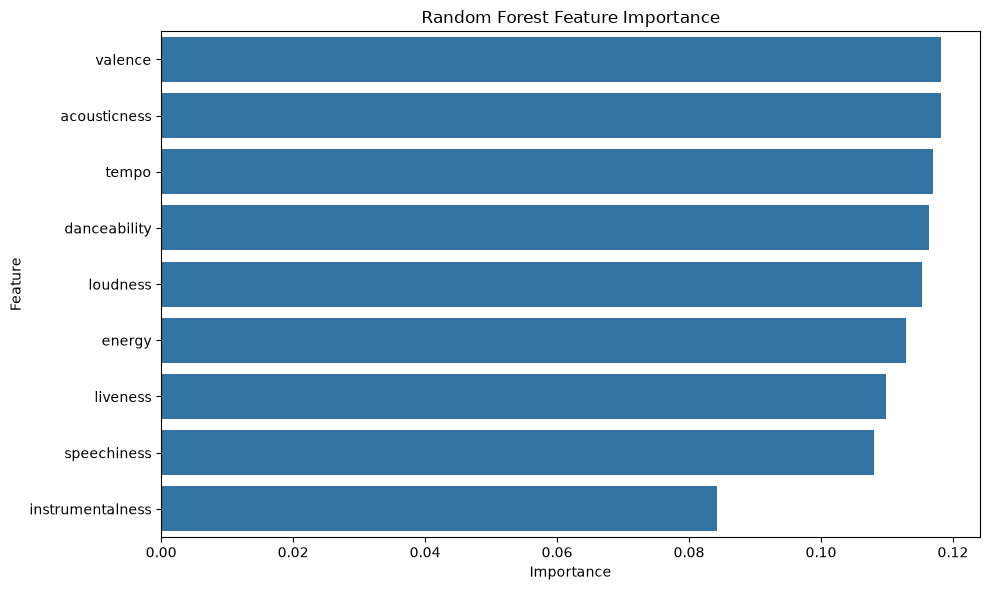

In [ ]:
#2. Feature Importance Graph
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance,
    x='Importance',
    y='Feature'
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [ ]:
#Create New Song
new_song = pd.DataFrame({
    'danceability': [0.80],
    'energy': [0.75],
    'loudness': [-5.0],
    'speechiness': [0.05],
    'acousticness': [0.10],
    'instrumentalness': [0.01],
    'liveness': [0.10],
    'valence': [0.80],
    'tempo': [120]
})

print("===== New Song Features =====")
display(new_song)

===== New Song Features =====


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
0,0.8,0.75,-5.0,0.05,0.1,0.01,0.1,0.8,120


In [ ]:
# Prediction Popularity
prediction = random_forest.predict(new_song)

print("===== Prediction Result =====")
print("Predicted Popularity Category:", prediction[0])

===== Prediction Result =====
Predicted Popularity Category: Moderately Popular


In [ ]:
# Prediction Probability
probability = random_forest.predict_proba(new_song)

print("===== Prediction Probabilities =====")

for category, prob in zip(
    random_forest.classes_,
    probability[0]
):
    print(f"{category}: {prob * 100:.2f}%")

===== Prediction Probabilities =====
Moderately Popular: 45.37%
Not Popular: 42.35%
Popular: 12.29%
